In [8]:
import pandas as pd
import numpy as np
import torch

from rtdl_revisiting_models import FTTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

import os
from dotenv import load_dotenv

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA T1000 8GB


In [7]:
FTTransformer.get_default_kwargs()

{'n_blocks': 3,
 'd_block': 192,
 'attention_n_heads': 8,
 'attention_dropout': 0.2,
 'ffn_d_hidden': None,
 'ffn_d_hidden_multiplier': 1.3333333333333333,
 'ffn_dropout': 0.1,
 'residual_dropout': 0.0,
 '_is_default': True}

In [9]:
load_dotenv()

df = pd.read_csv(os.getenv("DATA_PATH"), low_memory=False)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10261, 2040)


,ACN,Report Classification,Time Date,Time LocalTimeOfDay / 0001 - 0600,Time LocalTimeOfDay / 0601 - 1200,Time LocalTimeOfDay / 1201 - 1800,Time LocalTimeOfDay / 1801 -2400,Time LocalTimeOfDay / Not Stated,Environment Weather / Clear,Environment Weather / Fog,...,Assessments PrimaryProblem / Staffing,Assessments PrimaryProblem / Station / Platform,Assessments PrimaryProblem / Track / Structures,Assessments PrimaryProblem / Train / On Track Equipment,Assessments PrimaryProblem / Training / Qualification,Assessments PrimaryProblem / Weather,Assessments PrimaryProblem / Workplace Documentation,Assessments PrimaryProblem / Yard Configuration,Assessments PrimaryProblem / Ambiguous,Synopsis
0,42788,Full Form Analysis,2026-07,NaN,True,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A Train Crew reported a Class II Brake Test wa...
1,42787,Full Form Analysis,2026-07,NaN,True,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,An Engineer reported a vehicle was struck at a...
2,42786,Full Form Analysis,2026-07,NaN,NaN,True,NaN,NaN,True,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A Conductor reported a train was not spotted c...
3,42784,Full Form Analysis,2026-07,True,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,A Train Crew reported a hand brake malfunction...
4,42783,Full Form Analysis,2026-07,True,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A Maintenance of Way Foreman released a Moveme...


In [12]:
df.columns = [" ".join(str(c).split()) for c in df.columns]

target_cols = [
    "Events Anomaly / Operating Cab / Car Event - Station Operations",
    "Events Anomaly / Speed Deviation - Maximum Authorized Speed",
    "Events Anomaly / Braking Event - Emergency / Penalty Brake Application",
    "Events Anomaly / Mechanical - Less Severe",
    "Events Anomaly / Signal Events - On Board Control System",
    "Events Anomaly / Speed Deviation - Temporary Speed Restriction",
]

In [22]:
y = df[target_cols].notna().astype(np.float32).to_numpy()

print("Target shape:", y.shape)
print("Positive reports per category:", y.sum(axis=0).astype(int))

Target shape: (10261, 6)
Positive reports per category: [2541 2042 1848 1657 1430 1373]


In [25]:
df = df.loc[:, df.nunique(dropna=False) > 1].copy()

print("Dataset shape:", df.shape)
print("All targets retained:", all(c in df.columns for c in target_cols))

Dataset shape: (10261, 991)
All targets retained: True


In [26]:
exclude_groups = {
    "ACN", "Report Classification", "Time Date", "Synopsis",
    "Person Narrative", "Person Callback",
    "Person C3RS Report Number", "Person TrainReference"
}

exclude_families = {"Events", "Assessments", "Component"}

feature_cols = [
    c for c in df.columns
    if c.split(" / ")[0] not in exclude_groups
    and c.split()[0] not in exclude_families
]

print("Candidate tabular features:", len(feature_cols))

Candidate tabular features: 762


In [28]:
train_fields = sorted({
    c.rsplit(" ", 1)[0] if c.rsplit(" ", 1)[-1].isdigit() else c
    for c in feature_cols
    if c.startswith("Train /")
})

print("Distinct Train fields:", len(train_fields))
print(*train_fields, sep="\n")

Distinct Train fields: 113
Train / Equipment BrakeSystems / Applied Prior
Train / Equipment BrakeSystems / Automated Braking Systems
Train / Equipment BrakeSystems / Blended Brakes
Train / Equipment BrakeSystems / Dynamic Brakes
Train / Equipment BrakeSystems / Electric Brakes
Train / Equipment BrakeSystems / Hand Brake
Train / Equipment BrakeSystems / Independent Air
Train / Equipment BrakeSystems / Operational Prior
Train / Equipment BrakeSystems / Train Air Brakes
Train / Equipment BrakeSystems / Unknown
Train / Equipment EmergencyBrakesApplied / Emergency Brakes Applied
Train / Equipment Equipment / Cab Car Controlling
Train / Equipment Equipment / Control Stand Type
Train / Equipment Equipment / Controlling Locomotive
Train / Equipment Equipment / Crane
Train / Equipment Equipment / Forklift
Train / Equipment Equipment / Motor Vehicle
Train / Equipment Equipment / Number In Service
Train / Equipment Equipment / Number Of Cars
Train / Equipment Equipment / Off Track Equipment
Train

In [29]:
def infer_type(series):
    values = series.dropna().astype(str).str.strip()

    if values.str.fullmatch(r"(?i:true|false)").all():
        return "binary"

    if pd.to_numeric(values, errors="coerce").notna().all():
        return "numerical"

    return "categorical"


feature_types = {c: infer_type(df[c]) for c in feature_cols}

num_cols = [c for c in feature_cols if feature_types[c] == "numerical"]
cat_cols = [c for c in feature_cols if feature_types[c] == "categorical"]
bin_cols = [c for c in feature_cols if feature_types[c] == "binary"]

print("Numerical:", len(num_cols))
print("Categorical:", len(cat_cols))
print("Binary:", len(bin_cols))
print("Total:", len(num_cols) + len(cat_cols) + len(bin_cols))

Numerical: 26
Categorical: 55
Binary: 681
Total: 762


In [30]:
converted = []

for col in cat_cols:
    s = df[col].astype("string").str.strip()
    s = s.str.replace(r'^="(.+)"$', r'\1', regex=True)

    pattern = r'\d+(?:\.\d+)?(?:-\d+(?:\.\d+)?|\+)?'

    if s.dropna().str.fullmatch(pattern).all():
        bounds = s.str.extract(
            r'^(\d+(?:\.\d+)?)(?:-(\d+(?:\.\d+)?))?\+?$'
        ).astype(float)

        df[col] = bounds.mean(axis=1)
        converted.append(col)

num_cols.extend(converted)
cat_cols = [c for c in cat_cols if c not in converted]

print("Converted to numerical:", len(converted))
print("Numerical:", len(num_cols))
print("Categorical:", len(cat_cols))
print("Binary:", len(bin_cols))

Converted to numerical: 29
Numerical: 55
Categorical: 26
Binary: 681


In [31]:
X = df[feature_cols].copy()

# Keep numerical measurements as numbers
X[num_cols] = X[num_cols].apply(pd.to_numeric, errors="coerce")

# Convert True/False to 1/0, preserving missing values
X[bin_cols] = X[bin_cols].apply(
    lambda s: s.astype("string").str.strip().str.lower()
    .map({"true": 1, "false": 0})
)

print("Tabular shape:", X.shape)
print("Numerical:", len(num_cols))
print("Categorical:", len(cat_cols))
print("Binary:", len(bin_cols))

Tabular shape: (10261, 762)
Numerical: 55
Categorical: 26
Binary: 681


In [32]:
from sklearn.model_selection import train_test_split

train_idx, remaining_idx = train_test_split(
    np.arange(len(X)),
    test_size=0.30,
    random_state=42
)

val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=42
)

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"{name}: {len(idx):,} reports")
    print("Positive labels:", y[idx].sum(axis=0).astype(int))

Train: 7,182 reports
Positive labels: [1798 1409 1322 1174 1017  958]
Validation: 1,539 reports
Positive labels: [380 320 256 242 202 207]
Test: 1,540 reports
Positive labels: [363 313 270 241 211 208]


In [33]:
missing = X[num_cols].isna()

print("Total reports:", len(X))
print("Reports with missing numerical values:", missing.any(axis=1).sum())
print("Reports with complete numerical values:", (~missing.any(axis=1)).sum())

print("\nPercentage of reports with missing values:")
print(f"{missing.any(axis=1).mean():.2%}")

print("\nMedian missing numerical fields per report:")
print(missing.sum(axis=1).median())

print("\nNumerical columns over 90% missing:")
print((missing.mean() > 0.90).sum())

Total reports: 10261
Reports with missing numerical values: 10261
Reports with complete numerical values: 0

Percentage of reports with missing values:
100.00%

Median missing numerical fields per report:
49.0

Numerical columns over 90% missing:
45


In [34]:
train_num = X.iloc[train_idx][num_cols]

mean = train_num.mean().fillna(0)
std = train_num.std(ddof=0).replace(0, 1).fillna(1)

# Standardize numerical measurements using training statistics
X_num = ((X[num_cols] - mean) / std).fillna(0).to_numpy(dtype=np.float32)

# Preserve information about which measurements were missing
X_missing = X[num_cols].isna().to_numpy(dtype=np.float32)

X_num = np.concatenate([X_num, X_missing], axis=1)

print("Numerical input shape:", X_num.shape)
print("Remaining NaNs:", np.isnan(X_num).sum())

Numerical input shape: (10261, 110)
Remaining NaNs: 0


In [35]:
from sklearn.preprocessing import OrdinalEncoder

# Categorical features: learn encodings from training data only
cat_values = X[cat_cols].fillna("__MISSING__").astype(str)

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

encoder.fit(cat_values.iloc[train_idx])

X_cat = encoder.transform(cat_values).astype(np.int64) + 1

# Binary features: preserve missing, False, and True separately
X_bin = X[bin_cols].fillna(-1).to_numpy(dtype=np.int64) + 1

# Combine categorical and binary inputs
X_cat = np.concatenate([X_cat, X_bin], axis=1)

cat_cardinalities = (
    [len(c) + 1 for c in encoder.categories_]
    + [3] * len(bin_cols)
)

print("Categorical input shape:", X_cat.shape)
print("Categorical cardinalities:", len(cat_cardinalities))

Categorical input shape: (10261, 707)
Categorical cardinalities: 707


In [37]:
from torch.utils.data import TensorDataset, DataLoader, Subset

dataset = TensorDataset(
    torch.from_numpy(X_num),
    torch.from_numpy(X_cat),
    torch.from_numpy(y)
)

batch_size = 32

train_loader = DataLoader(
    Subset(dataset, train_idx), batch_size=batch_size, shuffle=True
)

val_loader = DataLoader(
    Subset(dataset, val_idx), batch_size=batch_size
)

test_loader = DataLoader(
    Subset(dataset, test_idx), batch_size=batch_size
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 225
Validation batches: 49
Testing batches: 49


In [38]:
model = FTTransformer(
    n_cont_features=X_num.shape[1],
    cat_cardinalities=cat_cardinalities,
    d_out=y.shape[1],
    **FTTransformer.get_default_kwargs()
).to(device)

print("Device:", device)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Device: cuda
Trainable parameters: 1,527,366


In [39]:
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = model.make_default_optimizer()

In [40]:
import copy

epochs = 30
patience = 5
best_loss = float("inf")
wait = 0
history = []

for epoch in range(epochs):
    model.train()
    train_loss = 0

    for x_cont, x_cat, labels in train_loader:
        x_cont = x_cont.to(device)
        x_cat = x_cat.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        loss = criterion(model(x_cont, x_cat), labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(labels)

    model.eval()
    val_loss = 0

    with torch.no_grad():
        for x_cont, x_cat, labels in val_loader:
            x_cont = x_cont.to(device)
            x_cat = x_cat.to(device)
            labels = labels.to(device)

            loss = criterion(model(x_cont, x_cat), labels)
            val_loss += loss.item() * len(labels)

    train_loss /= len(train_idx)
    val_loss /= len(val_idx)

    history.append((train_loss, val_loss))

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_loss:
        best_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping")
            break

model.load_state_dict(best_state)

Epoch 01 | Train Loss: 0.4623 | Val Loss: 0.3837
Epoch 02 | Train Loss: 0.3069 | Val Loss: 0.2280
Epoch 03 | Train Loss: 0.2150 | Val Loss: 0.1823
Epoch 04 | Train Loss: 0.1860 | Val Loss: 0.1720
Epoch 05 | Train Loss: 0.1711 | Val Loss: 0.1643
Epoch 06 | Train Loss: 0.1660 | Val Loss: 0.1609
Epoch 07 | Train Loss: 0.1607 | Val Loss: 0.1602
Epoch 08 | Train Loss: 0.1574 | Val Loss: 0.1578
Epoch 09 | Train Loss: 0.1513 | Val Loss: 0.1571
Epoch 10 | Train Loss: 0.1490 | Val Loss: 0.1550
Epoch 11 | Train Loss: 0.1460 | Val Loss: 0.1565
Epoch 12 | Train Loss: 0.1437 | Val Loss: 0.1529
Epoch 13 | Train Loss: 0.1390 | Val Loss: 0.1564
Epoch 14 | Train Loss: 0.1375 | Val Loss: 0.1641
Epoch 15 | Train Loss: 0.1352 | Val Loss: 0.1596
Epoch 16 | Train Loss: 0.1328 | Val Loss: 0.1562
Epoch 17 | Train Loss: 0.1299 | Val Loss: 0.1561
Early stopping


<All keys matched successfully>

In [41]:
from sklearn.metrics import precision_recall_fscore_support, average_precision_score

model.eval()
probs, targets = [], []

with torch.no_grad():
    for x_cont, x_cat, labels in val_loader:
        logits = model(x_cont.to(device), x_cat.to(device))
        probs.append(torch.sigmoid(logits).cpu())
        targets.append(labels)

y_true = torch.cat(targets).numpy().astype(int)
y_prob = torch.cat(probs).numpy()
y_pred = (y_prob >= 0.5).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0
)

ap = average_precision_score(y_true, y_prob, average=None)

results = pd.DataFrame({
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "AP": ap
}, index=[c.split(" / ")[-1] for c in target_cols])

print(results.round(3))
print("\nMacro F1:", round(f1.mean(), 3))
print("Macro AP:", round(ap.mean(), 3))

                                               Precision  Recall     F1     AP
Car Event - Station Operations                     0.953   0.858  0.903  0.967
Speed Deviation - Maximum Authorized Speed         0.955   0.925  0.940  0.956
Penalty Brake Application                          0.925   0.969  0.947  0.945
Mechanical - Less Severe                           0.684   0.483  0.567  0.620
Signal Events - On Board Control System            0.646   0.515  0.573  0.598
Speed Deviation - Temporary Speed Restriction      0.956   0.947  0.951  0.979

Macro F1: 0.813
Macro AP: 0.844


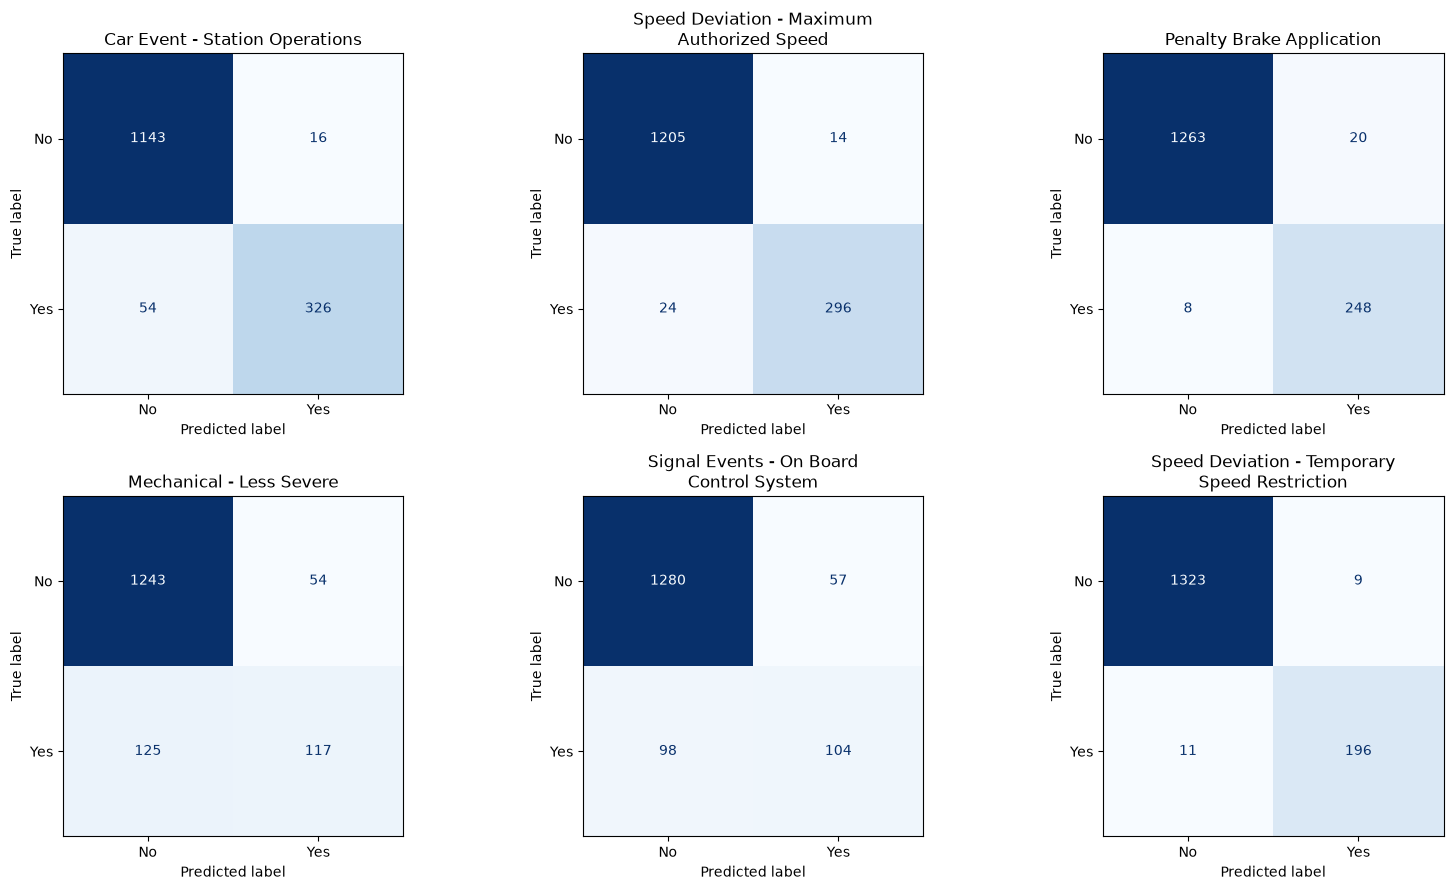

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay
from textwrap import fill

cm = multilabel_confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    ConfusionMatrixDisplay(
        confusion_matrix=cm[i],
        display_labels=["No", "Yes"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

    ax.set_title(fill(target_cols[i].split(" / ")[-1], 30))

plt.tight_layout()
plt.show()